# Measurement-induced phase transition: a tour

Picture a quantum computer running a random circuit with random local unitary gates and random measurements, and look at the two extreme scenarios

- **No measurements.** The whole circuit is one big unitary matrix, and a random one. It entangles every qubit with every other, so any group of qubits (up to half the system) is close to maximally entangled with the rest.
- **Every qubit measured after every step.** Each measurement collapses its qubit, so the state ends as a product state: a string of 0s and 1s, with no entanglement and no more structure than the initial state $|00\cdots0\rangle$.

In between, random gates and random measurements compete. At a critical measurement rate $p_c$ the entanglement changes character abruptly: this is the *measurement-induced phase transition* (MIPT). For background, see the review by [Fisher, Khemani, Nahum & Vijay, arXiv:2207.14280](https://arxiv.org/abs/2207.14280) (Annu. Rev. Condens. Matter Phys. 14, 335 (2023)).

This notebook shows:

1. the circuits we sample,
2. the entanglement entropy of a block of qubits across the transition (**area law versus volume law**),
3. **entanglement-weighted graphs** ([Lyu et al., arXiv:2602.04969](https://arxiv.org/abs/2602.04969)): which measurement patterns in spacetime produce entanglement between two distant pairs of qubits,
4. how entanglement between distant regions decays at the critical point, from the same paper.

All simulations use `mipt_sim`, a dense state-vector simulator in NumPy. Each result comes twice: a small version you can run here in seconds, then the full result, computed by a script in `scripts/` and loaded from `results/`.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import MaxNLocator

from mipt_sim import interval_entropy, random_circuit, run_circuit, run_trajectory
from mipt_sim.ewg import sample, summarize

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

## 1. The circuit

A ring of *L* qubits starts in $|00\cdots0\rangle$. Each time step has two parts:

- **Gates.** Two-qubit gates act on neighbouring pairs in a brickwork pattern: pairs (0,1), (2,3), … on even steps and (1,2), (3,4), …, (L−1, 0) on odd steps. The chain is **periodic**, so the last qubit couples back to the first. Each gate is an independent random unitary drawn from the [Haar measure](https://en.wikipedia.org/wiki/Haar_measure) on U(4), the "most random" two-qubit gate.
- **Measurements.** Each qubit is then measured in the computational basis with probability *p*. The outcome is random, drawn with the Born rule, and the state collapses accordingly.

One such random circuit, with its random measurement locations, is a *circuit realization*. Running it once, with random measurement outcomes, is a *trajectory*. Below is one realization for L = 6 over four time steps, drawn with PennyLane's `qml.draw_mpl` (wires are labelled from 0 here). The tall box spanning all wires is the gate that closes the ring on qubits 5 and 0: it acts only on those two, at the tabs.

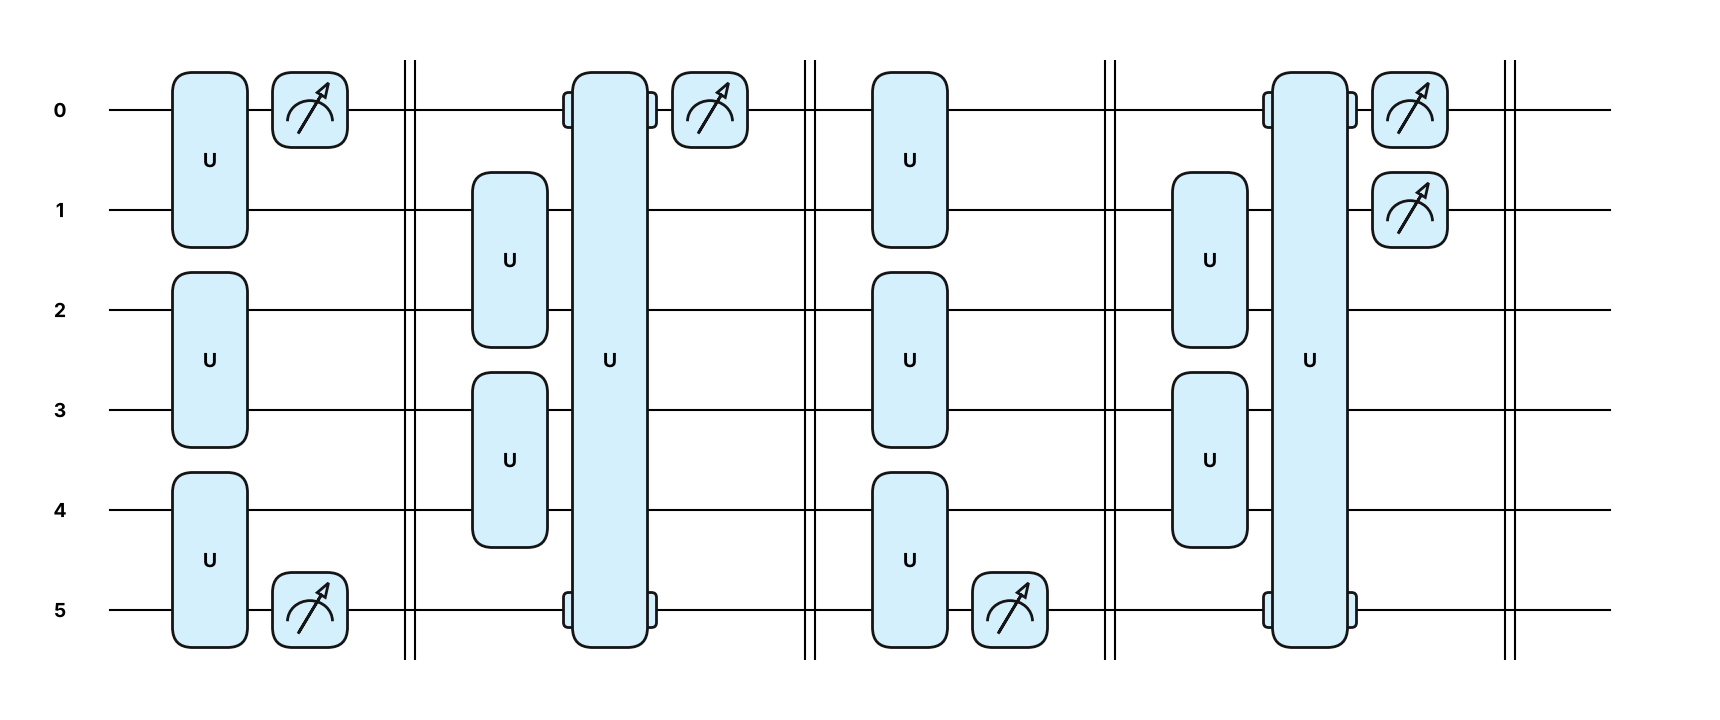

In [2]:
import pennylane as qml

L_demo = 6
layers = random_circuit(L_demo, 0.25, np.random.default_rng(3), depth=4)


def demo_circuit():
    for gates, measured in layers:
        for wires, u in gates:
            qml.QubitUnitary(u, wires=wires)
        for q in measured:
            qml.measure(q)
        qml.Barrier(wires=range(L_demo), only_visual=True)


fig, ax = qml.draw_mpl(demo_circuit, wire_order=range(L_demo), style="pennylane")()

## 2. Area law versus volume law

How entangled is a block of ℓ consecutive qubits with the rest of the ring? The [von Neumann entropy](https://en.wikipedia.org/wiki/Von_Neumann_entropy) *S* of the block counts this in bits: *S* = 0 for a product state, and at most *S* = ℓ.

The two ends of the phase diagram are easy to picture:

- At **p = 0** the circuit is one big random unitary, and the block is almost maximally entangled with the rest: *S* is close to ℓ. For a uniformly random state this is [Page's formula](https://arxiv.org/abs/gr-qc/9305007) (Phys. Rev. Lett. 71, 1291 (1993)).
- At **p = 1** every qubit is measured after every step, so the state is a product state, a single bit string, and *S* = 0.

In between, *S* either keeps growing in proportion to ℓ (**volume law**: the gates win) or stops growing after a few qubits (**area law**: the measurements win; in one dimension the "area" of a block is just its two end points). For random Haar gates on qubits, the transition sits near $p_c \approx 0.17$ ([Zabalo et al., arXiv:1911.00008](https://arxiv.org/abs/1911.00008), Phys. Rev. B 101, 060301 (2020)).

First, the entropy of half the ring along two single trajectories at L = 14: it grows from zero and saturates within a few time steps, at very different levels.

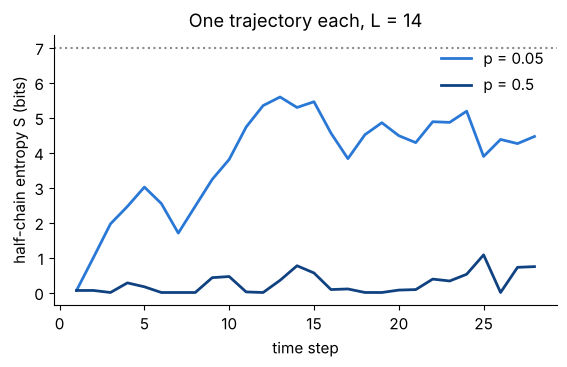

In [3]:
L, depth = 14, 28
fig, ax = plt.subplots(figsize=(6.5, 3.5))
for p, c in [(0.05, "#2a78d6"), (0.5, "#104281")]:
    rng = np.random.default_rng(1)
    _, s = run_circuit(L, random_circuit(L, p, rng, depth), rng, record=True)
    ax.plot(range(1, depth + 1), s, color=c, lw=2, label=f"p = {p}")
ax.axhline(L / 2, ls=":", color="#8a8a86")
ax.set(xlabel="time step", ylabel="half-chain entropy S (bits)", title=f"One trajectory each, L = {L}")
ax.legend(frameon=False);

Now *S* versus the block size ℓ, averaged over trajectories. This small version (L = 10, 20 trajectories per *p*) runs in a few seconds; change `ps` or `L` to explore.

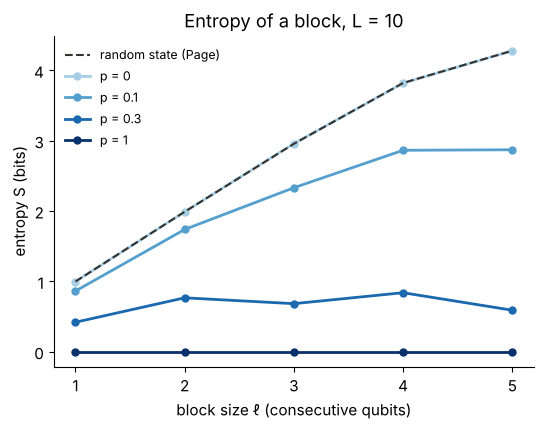

In [4]:
def page(l, n):  # average entropy (bits) of l qubits in a uniformly random state of n qubits
    m, k = 2**l, 2 ** (n - l)
    return (sum(1 / j for j in range(k + 1, m * k + 1)) - (m - 1) / (2 * k)) / np.log(2)


def plot_entropy(ell, ps, means, L, ax):
    ax.plot(ell, [page(l, L) for l in ell], ls="--", color="#33332f", zorder=3, label="random state (Page)")
    colors = plt.cm.Blues(np.linspace(0.35, 1, len(ps)))  # light = few measurements, dark = many
    for p, m, color in zip(ps, means, colors):
        ax.plot(ell, m, color=color, lw=2, marker="o", ms=5, label=f"p = {p:g}")
    ax.set(xlabel="block size ℓ (consecutive qubits)", ylabel="entropy S (bits)", title=f"Entropy of a block, L = {L}")
    ax.set_xticks(ell)
    ax.legend(frameon=False, fontsize=9)


L, ps, n_traj = 10, [0.0, 0.1, 0.3, 1.0], 20
ell = range(1, L // 2 + 1)
rng = np.random.default_rng(0)
means = []
for p in ps:
    psis = [run_trajectory(L, p, rng) for _ in range(n_traj)]
    means.append([np.mean([interval_entropy(psi, l) for psi in psis]) for l in ell])
fig, ax = plt.subplots(figsize=(6.2, 4.3))
plot_entropy(list(ell), ps, means, L, ax)

The full result at L = 20, with 100 trajectories per *p*, comes from `scripts/subregion.py` (about 10 minutes on a 12-core laptop).

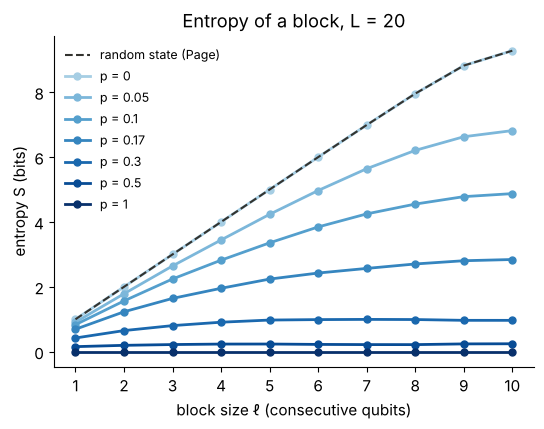

In [5]:
with open("../results/subregion_L20.json") as f:
    sub = json.load(f)
fig, ax = plt.subplots(figsize=(6.2, 4.3))
plot_entropy(sub["ell"], sub["p"], sub["mean"], sub["L"], ax)

At *p* = 0 the entropy follows the random-state curve, nearly the maximum ℓ. At *p* = 0.05 and 0.1 it still grows in proportion to ℓ, with a smaller slope: volume law. At *p* = 0.3 and 0.5 it saturates after two to four qubits: area law. At *p* = 1 it is exactly zero. Near $p_c \approx 0.17$ it keeps growing, but slowly, like log ℓ. All curves flatten near ℓ = L/2 because a block and the rest of the ring have the same entropy.

## 3. Entanglement-weighted graphs

At the critical point, two distant regions are *usually* not entangled at all. When they are, it is because the random measurements happened to fall in a favourable pattern. An **entanglement-weighted graph** (EWG) ([Lyu et al., arXiv:2602.04969](https://arxiv.org/abs/2602.04969), Sec. III B) shows that pattern on average. For every trajectory $\varepsilon$ we keep its measurement record $W_\varepsilon(x, t)$, equal to 1 if qubit *x* was measured at time *t* and 0 otherwise, and the entanglement $E(\varepsilon)$ it produced between regions *A* and *B* at the end. The graph is the entanglement-weighted average of the records,

$$
W[E](x, t) = \frac{\sum_\varepsilon E(\varepsilon)\, W_\varepsilon(x, t)}{\sum_\varepsilon E(\varepsilon)} .
$$

Where the measurements do not matter, this equals the bare rate *p* (white). Blue marks places measured *less* often than usual in the circuits that produced entanglement; red marks places measured *more* often.

The weight *E* is the [negativity](https://en.wikipedia.org/wiki/Negativity_(quantum_mechanics)) between *A* and *B*. Every trajectory is also counted mirrored, which swaps *A* and *B*, so that circuits ending on even and odd brickwork layers count equally.

Again a small version first: L = 10, *A* = qubits (1, 2) and *B* = (5, 6), 2,000 trajectories, about 15 seconds.

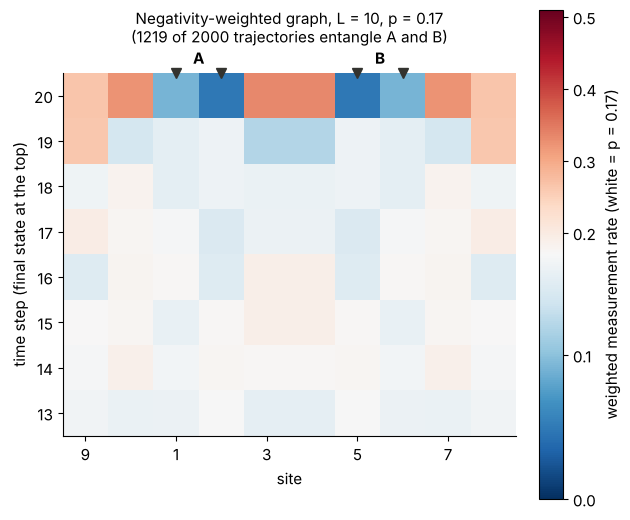

In [6]:
def plot_ewg(s, layers=20, ax=None):
    p, L = float(s["p"]), int(s["L"])
    A, B = list(s["A"]), list(s["B"])
    g = s["graph"][-layers:]
    t0 = len(s["graph"]) - layers  # time steps shown: t0 + 1 ... depth
    shift = (L - 1 - A[0] - B[-1]) // 2  # roll the ring so A and B sit in the middle
    cols = (np.arange(L) - shift) % L
    if ax is None:
        _, ax = plt.subplots(figsize=(6.2, 6.2), constrained_layout=True)
    norm = TwoSlopeNorm(vcenter=p, vmin=0.0, vmax=3 * p)  # values above 3p saturate
    im = ax.imshow(
        np.roll(g, shift, axis=1),
        origin="lower",
        cmap="RdBu_r",
        norm=norm,
        aspect="equal",
        extent=(0.5, L + 0.5, t0 + 0.5, t0 + layers + 0.5),
    )
    ax.set_xticks(range(1, L + 1, 2), [str(cols[i] + 1) for i in range(0, L, 2)])
    ax.set_xlabel("site")
    ax.set_ylabel("time step (final state at the top)")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    top = t0 + layers + 0.5
    for q, lab in [(A, "A"), (B, "B")]:
        q = [(x + shift) % L for x in q]
        ax.annotate(
            lab,
            ((q[0] + q[-1]) / 2 + 1, top),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontweight="bold",
            annotation_clip=False,
        )
        for x in q:
            ax.plot([x + 1], [top], marker="v", color="#33332f", ms=7, clip_on=False)
    ax.set_xlim(0.5, L + 0.5)
    ax.set_ylim(t0 + 0.5, top)
    ax.set_title(
        f"Negativity-weighted graph, L = {L}, p = {p:g}\n({int(s['n_entangled'])} of {int(s['n'])} trajectories entangle A and B)",
        pad=22,
        fontsize=11,
    )
    plt.colorbar(im, ax=ax, shrink=0.8, label=f"weighted measurement rate (white = p = {p:g})")
    return ax


L, p, A, B = 10, 0.17, [0, 1], [4, 5]  # 0-based labels
records, weights = [], []
for seed in range(2000):
    record, w = sample(L, p, A, B, seed)
    records.append(record)
    weights.append(w["negativity"])
plot_ewg(summarize(np.array(records), np.array(weights), L, p, A, B), layers=8);

The full result at L = 18, p = 0.17, with *A* = qubits (1, 2) and *B* = (8, 9), averages about 260,000 trajectories from `scripts/ewg_run.py` (a few hours on a laptop). Only the averaged graph is stored, in `results/ewg_graph_L18_p0.17.npz`.

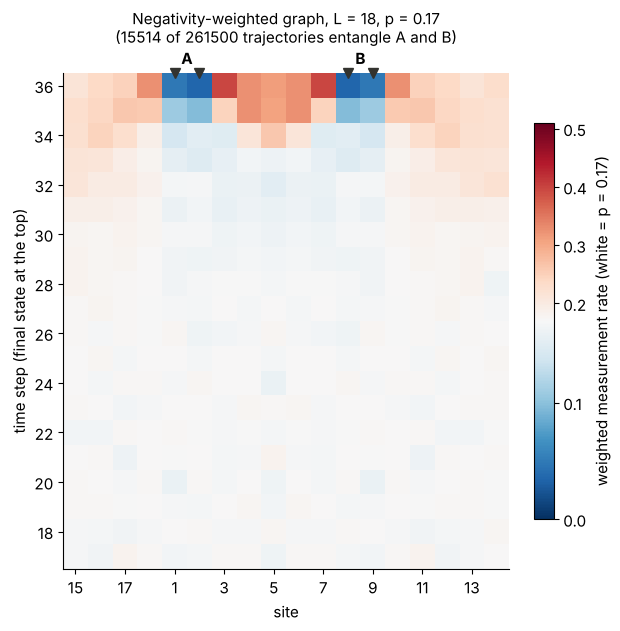

In [7]:
plot_ewg(np.load("../results/ewg_graph_L18_p0.17.npz"), layers=20);

What the graph shows:

- **A and B themselves are almost never measured at the end.** Measuring a qubit of A or B just before the end destroys its entanglement.
- **The qubits between A and B are measured *more* often in the last two layers**, about twice the rate p. A plausible reading is **entanglement swapping**: measuring the qubits that mediate the correlation can transfer their entanglement onto A and B.
- **A low-measurement bulk joins A and B** a few time steps before the end: entanglement between them needs an unmeasured patch of spacetime connecting them, as in the paper's Fig. 6.
- **A red halo surrounds it.** The far side of the ring is measured more often. Measuring there cuts A and B off from the rest of the chain, so their entanglement is not shared away.
- **Deeper in the past the graph returns to p.**

The paper uses Mølmer–Sørensen gates rather than Haar gates, yet both show the same bulk-and-halo structure.

## 4. How entanglement decays with distance

The figure below is Fig. 4(b) of [Lyu et al., arXiv:2602.04969](https://arxiv.org/abs/2602.04969). It shows, at the critical point, how the genuine multiparty negativity between *k* distant regions falls off with their separation *d*, for *k* = 2 (red), 3 (blue) and 4 (purple) parties and sizes L = 18 to 26 (light to dark). It decays as a steep power law, about $d^{-8.8}$ for two parties, and faster for more parties. That steep decay is why the negativity above was zero in most trajectories.

One difference to keep in mind: the paper uses a trapped-ion gate set ([Mølmer–Sørensen](https://en.wikipedia.org/wiki/M%C3%B8lmer%E2%80%93S%C3%B8rensen_gate) gates dressed with random single-qubit rotations) rather than Haar-random gates. Both have their transition near *p* = 0.17.

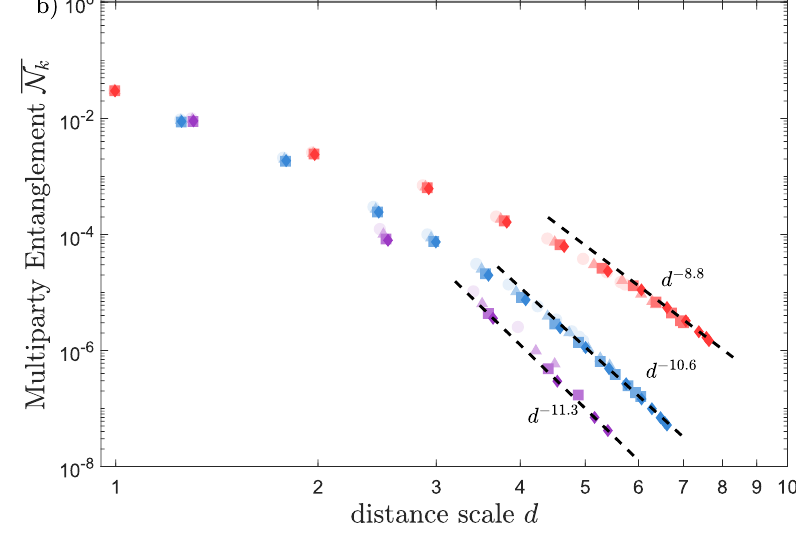

In [8]:
Image("figures/fig4b_arXiv2602.04969.png", width=560)

## Notes

- **Simulator.** `mipt_sim.numpy_sim` stores the state as a `(2,)*L` tensor and applies each gate with one `np.tensordot`.
- **PennyLane.** Besides drawing the circuit, PennyLane checks the simulator: `mipt_sim.pennylane_check.circuit_qnode` builds the same monitored circuit with `qml.measure`, and the tests compare our trajectory averages with PennyLane's exact outcome-averaged values. PennyLane cannot run this study by itself, because in exact mode it never returns the post-measurement state of a single trajectory (see the README).